In [3]:
from pathlib import Path

dataset_path = Path(
    r"C:\Users\saman\OneDrive\Desktop\OG flower dataset\archive\102 flower"
)

flowers_path = dataset_path / "flowers"

train_path = flowers_path / "train"

print("Training folder:")
print(train_path)

print("\nTraining folder exists:")
print(train_path.exists())

Training folder:
C:\Users\saman\OneDrive\Desktop\OG flower dataset\archive\102 flower\flowers\train

Training folder exists:
True


In [4]:
from torchvision import transforms

# Preprocessing 
train_transforms = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


valid_test_transforms = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


print("Training transformations created.")
print("Validation/test transformations created.")

Training transformations created.
Validation/test transformations created.


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].


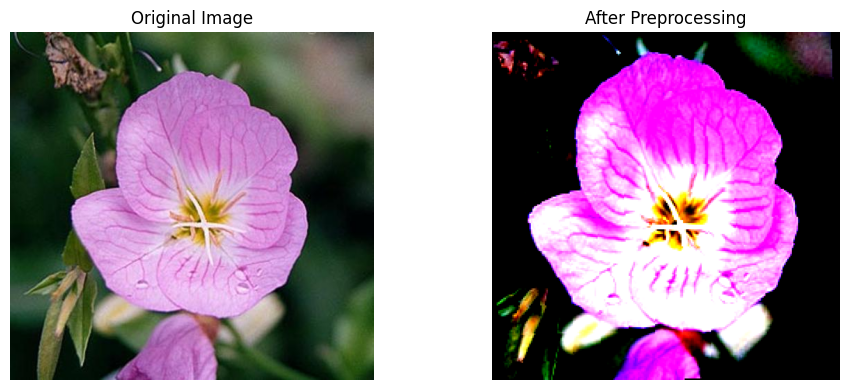

In [5]:
from PIL import Image
import matplotlib.pyplot as plt

first_class_folder = next(train_path.iterdir())
first_image_file = next(first_class_folder.iterdir())

original_image = Image.open(first_image_file)

processed_image = train_transforms(original_image)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(original_image)
plt.title("Original Image")
plt.axis("off")


processed_image_display = processed_image.permute(1, 2, 0)

plt.subplot(1, 2, 2)
plt.imshow(processed_image_display)
plt.title("After Preprocessing")
plt.axis("off")

plt.tight_layout()
plt.show()

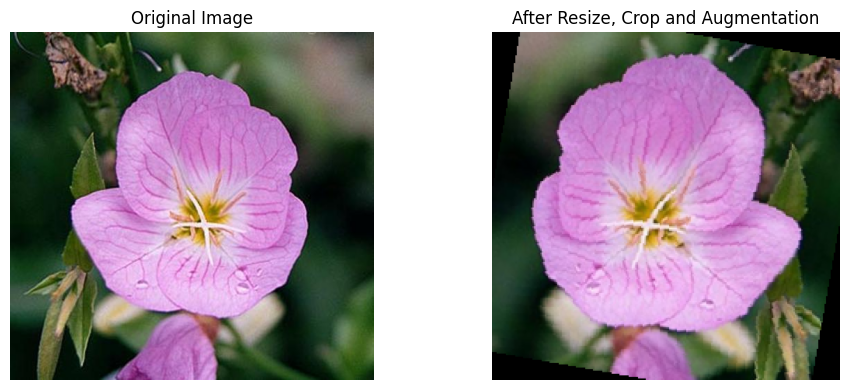

In [6]:
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt

first_class_folder = next(train_path.iterdir())
first_image_file = next(first_class_folder.iterdir())

original_image = Image.open(first_image_file)

visual_transforms = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor()
])

processed_image = visual_transforms(original_image)


processed_image_display = processed_image.permute(1, 2, 0)


plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(original_image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(processed_image_display)
plt.title("After Resize, Crop and Augmentation")
plt.axis("off")

plt.tight_layout()
plt.show()

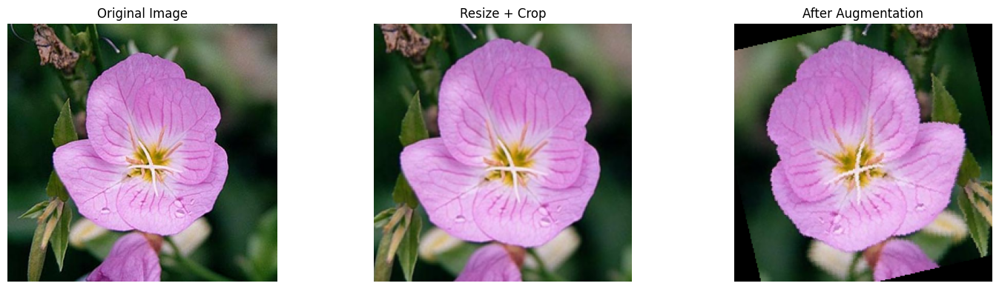

In [7]:
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt

first_class_folder = next(train_path.iterdir())
first_image_file = next(first_class_folder.iterdir())

original_image = Image.open(first_image_file)

resize_crop = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224)
])

resized_image = resize_crop(original_image)


augmentation = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15)
])

augmented_image = augmentation(resized_image)

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.imshow(original_image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(resized_image)
plt.title("Resize + Crop")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(augmented_image)
plt.title("After Augmentation")
plt.axis("off")

plt.tight_layout()
plt.show()

In [8]:

print("Original image size:", original_image.size)
print("Processed image size:", resized_image.size)

Original image size: (523, 500)
Processed image size: (224, 224)


In [9]:

normalized_image = train_transforms(original_image)

print("Processed image shape:", normalized_image.shape)
print("Minimum pixel value:", normalized_image.min().item())
print("Maximum pixel value:", normalized_image.max().item())

Processed image shape: torch.Size([3, 224, 224])
Minimum pixel value: -2.1179039478302
Maximum pixel value: 2.640000104904175


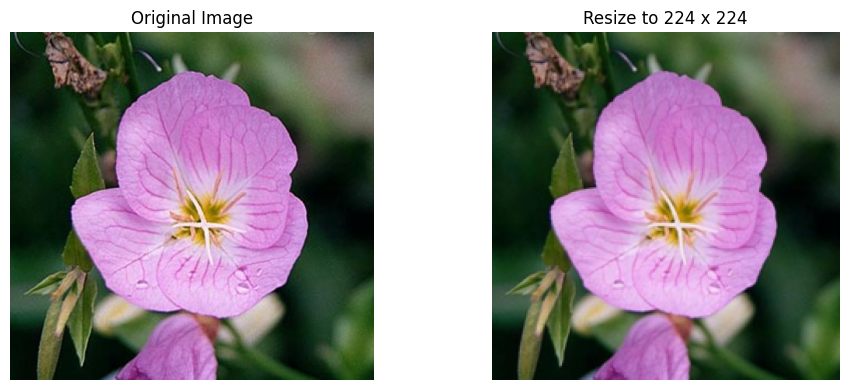

In [10]:
from torchvision import transforms
import matplotlib.pyplot as plt

resize_only = transforms.Resize((224, 224))

resized_image = resize_only(original_image)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(original_image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(resized_image)
plt.title("Resize to 224 x 224")
plt.axis("off")

plt.tight_layout()
plt.show()

Original size: (523, 500)
Resized size: (234, 224)


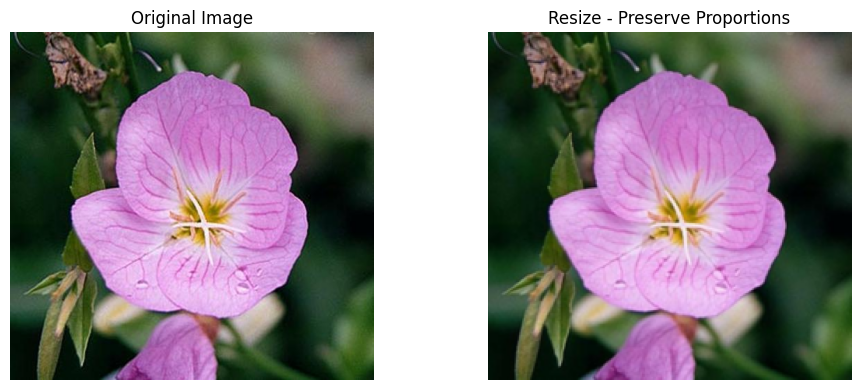

In [11]:
from torchvision import transforms
import matplotlib.pyplot as plt

resize_preserve_ratio = transforms.Resize(224)

preserved_image = resize_preserve_ratio(original_image)

print("Original size:", original_image.size)
print("Resized size:", preserved_image.size)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(original_image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(preserved_image)
plt.title("Resize - Preserve Proportions")
plt.axis("off")

plt.tight_layout()
plt.show()

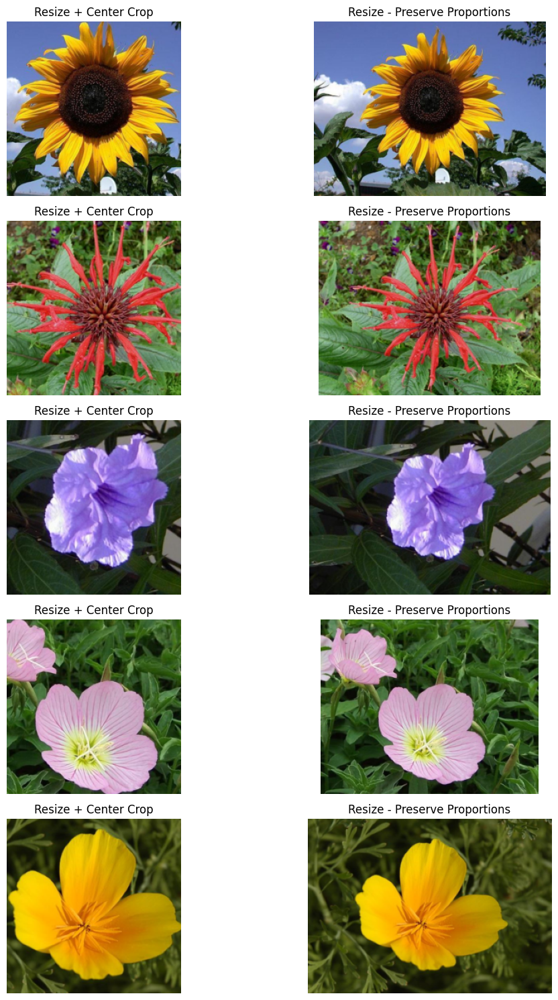

In [12]:
import random
from PIL import Image
import matplotlib.pyplot as plt
from torchvision import transforms

all_images = []

for class_folder in train_path.iterdir():
    if class_folder.is_dir():
        for image_file in class_folder.iterdir():
            if image_file.is_file():
                all_images.append(image_file)

random_images = random.sample(all_images, 5)

crop_method = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224)
])

preserve_method = transforms.Resize(224)

plt.figure(figsize=(12, 15))

for i in range(5):

    image = Image.open(random_images[i])

    crop_image = crop_method(image)
    preserve_image = preserve_method(image)

    plt.subplot(5, 2, i * 2 + 1)
    plt.imshow(crop_image)
    plt.title("Resize + Center Crop")
    plt.axis("off")

    plt.subplot(5, 2, i * 2 + 2)
    plt.imshow(preserve_image)
    plt.title("Resize - Preserve Proportions")
    plt.axis("off")

plt.tight_layout()
plt.show()

Original size: (523, 500)
After resize: (234, 224)
After padding: (224, 224)


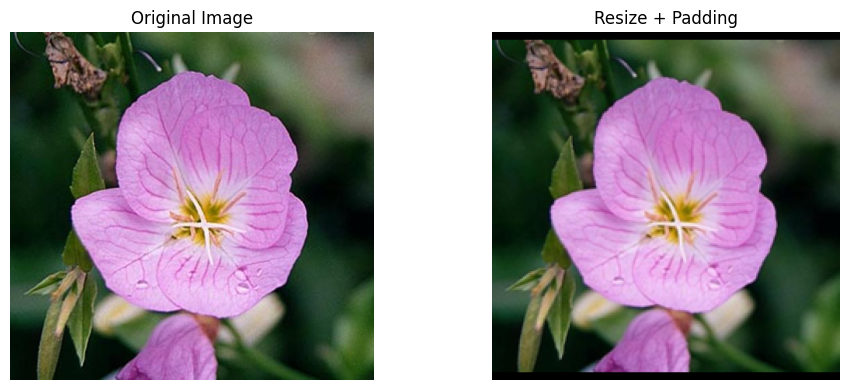

In [13]:
from PIL import Image, ImageOps
import matplotlib.pyplot as plt

resized_image = preserve_method(original_image)

padded_image = ImageOps.pad(
    resized_image,
    (224, 224),
    method=Image.Resampling.LANCZOS,
    color="black"
)

print("Original size:", original_image.size)
print("After resize:", resized_image.size)
print("After padding:", padded_image.size)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(original_image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(padded_image)
plt.title("Resize + Padding")
plt.axis("off")

plt.tight_layout()
plt.show()

In [14]:
print(len(random_images))
print(random_images[:5])

5
[WindowsPath('C:/Users/saman/OneDrive/Desktop/OG flower dataset/archive/102 flower/flowers/train/54/image_05455.jpg'), WindowsPath('C:/Users/saman/OneDrive/Desktop/OG flower dataset/archive/102 flower/flowers/train/92/image_03053.jpg'), WindowsPath('C:/Users/saman/OneDrive/Desktop/OG flower dataset/archive/102 flower/flowers/train/98/image_07775.jpg'), WindowsPath('C:/Users/saman/OneDrive/Desktop/OG flower dataset/archive/102 flower/flowers/train/1/image_06738.jpg'), WindowsPath('C:/Users/saman/OneDrive/Desktop/OG flower dataset/archive/102 flower/flowers/train/65/image_03194.jpg')]


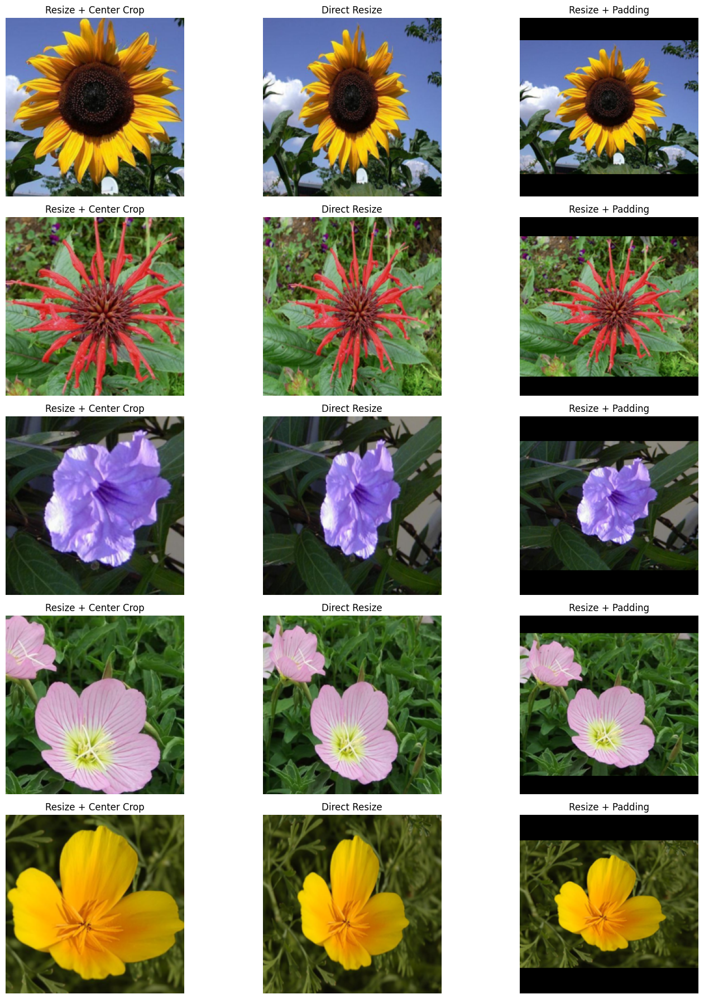

In [15]:
import matplotlib.pyplot as plt
from torchvision import transforms
from PIL import Image, ImageOps

crop_method = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224)
])

direct_resize = transforms.Resize((224, 224))

preserve_resize = transforms.Resize(224)

#############################################################
######### replaced this line with the one below to make the 
######### distortion more obvious. 
#########plt.figure(figsize=(12, 15))

plt.figure(figsize=(15, 18))
################################################################
for i in range(5):

    image = Image.open(random_images[i])

    crop_image = crop_method(image)

    direct_image = direct_resize(image)

    resized_image = preserve_resize(image)

    padded_image = ImageOps.pad(
        resized_image,
        (224, 224),
        method=Image.Resampling.LANCZOS,
        color="black"
    )

    plt.subplot(5, 3, i * 3 + 1)
    plt.imshow(crop_image)
    plt.title("Resize + Center Crop")
    plt.axis("off")

    plt.subplot(5, 3, i * 3 + 2)
    plt.imshow(direct_image)
    plt.title("Direct Resize")
    plt.axis("off")

    plt.subplot(5, 3, i * 3 + 3)
    plt.imshow(padded_image)
    plt.title("Resize + Padding")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [38]:
from torchvision import transforms
from PIL import Image, ImageOps

class ResizeAndPad:
    
    def __init__(self, size):
        self.size = size

    def __call__(self, image):
        
        width, height = image.size
        
        scale = min(self.size / width, self.size / height)
        
        new_width = int(width * scale)
        new_height = int(height * scale)
        
        image = image.resize(
            (new_width, new_height),
            Image.Resampling.LANCZOS
        )
        
        left = (self.size - new_width) // 2
        right = self.size - new_width - left
        top = (self.size - new_height) // 2
        bottom = self.size - new_height - top
        
        image = ImageOps.expand(
            image,
            border=(left, top, right, bottom),
            fill="black"
        )
        
        return image


resize_and_pad = ResizeAndPad(224)

print("Resize + Padding transformation created.")

Resize + Padding transformation created.


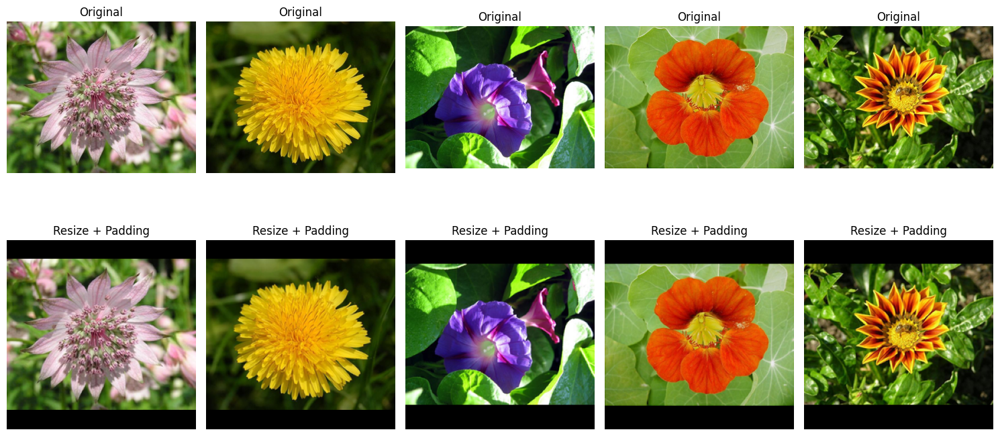

In [39]:
import matplotlib.pyplot as plt
from PIL import Image

plt.figure(figsize=(15, 8))

for i in range(5):

    image = Image.open(random_images[i])

    padded_image = resize_and_pad(image)

    plt.subplot(2, 5, i + 1)
    plt.imshow(image)
    plt.title("Original")
    plt.axis("off")

    plt.subplot(2, 5, i + 6)
    plt.imshow(padded_image)
    plt.title("Resize + Padding")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
train_transforms = transforms.Compose([
    transforms.Lambda(resize_and_pad),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Final training pipeline created.")

Final training pipeline created.


In [42]:
valid_test_transforms = transforms.Compose([
    transforms.Lambda(resize_and_pad),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Validation/test preprocessing pipeline created.")

Validation/test preprocessing pipeline created.


In [ ]:
from torchvision import datasets

train_dataset = datasets.ImageFolder(
    train_path,
    transform=train_transforms
)

valid_dataset = datasets.ImageFolder(
    flowers_path / "valid",
    transform=valid_test_transforms
)

test_dataset = datasets.ImageFolder(
    flowers_path / "test",
    transform=valid_test_transforms
)

print("Training images:", len(train_dataset))
print("Validation images:", len(valid_dataset))
print("Test images:", len(test_dataset))

In [43]:
from torchvision import datasets

train_dataset = datasets.ImageFolder(
    train_path,
    transform=train_transforms
)
valid_dataset = datasets.ImageFolder(
    flowers_path / "valid",
    transform=valid_test_transforms
)

test_dataset = datasets.ImageFolder(
    flowers_path / "test",
    transform=valid_test_transforms
)

print("Training images:", len(train_dataset))
print("Validation images:", len(valid_dataset))
print("Test images:", len(test_dataset))

Training images: 6552
Validation images: 818
Test images: 819


In [44]:
from torch.utils.data import DataLoader

batch_size = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(valid_loader))
print("Test batches:", len(test_loader))

Training batches: 205
Validation batches: 26
Test batches: 26


In [45]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
